<a href="https://colab.research.google.com/github/leejsya/MLProgramming/blob/main/week9/DL_MNIST_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library & Module Import

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Device

In [ ]:
# device 설정
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print(device)

mps


#### Transforms

In [ ]:
# preprocessing for training
transforms_train = v2.Compose(
    [
        # 이미지를 텐서로 변환
        v2.ToImage(),
        # 이미지 일부분 잘라내기 - 잘라낸 후 28크기로 resize
        v2.RandomResizedCrop(size=28, scale=(0.8, 1.0)),
        # 이미지 회전 - 최대 10도만큼
        v2.RandomRotation(degrees=10),
        # 픽셀값 데이터형 변환 및 스케일링 - float32, 0과 1 사이의 값으로 스케일링
        v2.ToDtype(dtype=torch.float32, scale=True),
        # MNIST 공식 mean, std 값 - split된 train dataset의 값과 큰 차이가 없어, 그대로 사용
        v2.Normalize(mean=[0.131], std=[0.308]),
    ]
)

# preprocessing for eval
transforms_eval = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(dtype=torch.float32, scale=True),
        # MNIST 공식 mean, std 값
        v2.Normalize(mean=[0.1307], std=[0.3081]),
    ]
)

#### Dataset

In [ ]:
seed = 42

''' Train Dataset '''
train_dataset = datasets.MNIST(
    root='./Data', # 데이터셋이 저장될 위치
    train=True,     # train dataset 추출
    download=True,  # 데이터셋 다운로드하기
    transform=transforms_train
)

''' Validation Dataset '''
val_dataset = datasets.MNIST(
    root='./Data', # 데이터셋이 저장될 위치
    train=True,     # train dataset 추출
    download=True,  # 데이터셋 다운로드하기
    transform=transforms_eval
)

''' Test Dataset '''
test_dataset = datasets.MNIST(
    root='./Data',
    train=False,   # test dataset 추출
    download=True,
    transform=transforms_eval
)

In [ ]:
''' stratum 비율을 유지하도록 인덱스를 분할'''
train_indices, val_indices = train_test_split(
    range(len(train_dataset)),
    # 50000 : 10000 : 10000
    test_size=1/6,
    stratify=train_dataset.targets,
    random_state=seed
)

train_dataset = Subset(train_dataset, train_indices)
val_dataset = Subset(val_dataset, val_indices)

#### DataLoader

In [ ]:
torch.manual_seed(seed)

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=128
)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=128
)

#### Model

In [ ]:
from torchvision.models import resnet18
from torchinfo import summary

# torchvision에서 제공하는 resnet18 모델 사용
model = resnet18(weights=None, num_classes=10)
summary(model, input_size=(1, 3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

In [ ]:
''' conv1 layer 세팅 변경 '''
# 채널 : 3채널 -> 1채널
# 커널사이즈 : 7 -> 3
# stride : 2 -> 1
# padding : 3 -> 1
model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
summary(model, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 64, 28, 28]           576
├─BatchNorm2d: 1-2                       [1, 64, 28, 28]           128
├─ReLU: 1-3                              [1, 64, 28, 28]           --
├─MaxPool2d: 1-4                         [1, 64, 14, 14]           --
├─Sequential: 1-5                        [1, 64, 14, 14]           --
│    └─BasicBlock: 2-1                   [1, 64, 14, 14]           --
│    │    └─Conv2d: 3-1                  [1, 64, 14, 14]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 14, 14]           128
│    │    └─ReLU: 3-3                    [1, 64, 14, 14]           --
│    │    └─Conv2d: 3-4                  [1, 64, 14, 14]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 14, 14]           128
│    │    └─ReLU: 3-6                    [1, 64, 14, 14]           --
│  

In [ ]:
model.to(device)
print()

#### Training Loop

In [ ]:
# Evaluation Function
def evaluate(dataloader, model, loss_fn):
    model.eval()
    losses = []
    correct, total = 0, 0
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            preds = model(inputs)

            loss = loss_fn(preds, labels)
            losses.append(loss.item())

            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

            # 각 배치의 예측값 텐서를 리스트에 저장
            all_preds.append(pred_labels.cpu())
            # 각 배치의 라벨값 텐서를 리스트에 저장
            all_labels.append(labels.cpu())

    # 각 배치의 예측값 텐서들을 행으로 이어붙임.
    all_preds = torch.cat(all_preds)
    # 각 배치의 라벨값 텐서들을 행으로 이어붙임.
    all_labels = torch.cat(all_labels)

    avg_loss = sum(losses) / len(losses)
    acc = correct / total

    return avg_loss, acc, all_preds, all_labels

In [ ]:
def Train_Loop(dataloader, model, loss_fn, optimizer, epochs, min_loss):
    step = 0
    train_loss_history = []
    train_acc_history = []
    val_loss_history = []
    val_acc_history = []

    for epoch in range(epochs):
        model.train()
        correct = 0
        total = 0
        losses = []

        for train_batch in dataloader:
            inputs, labels = train_batch[0].to(device), train_batch[1].to(device)
            preds = model(inputs)

            loss = loss_fn(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            step += 1
            if step % 100 == 0:
                print(f"(step {step}) train loss: {loss.item():.4f}")

            # train loss값 저장
            losses.append(loss.item())

            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

        # 평균 train loss값 추가
        train_loss_history.append(np.mean(losses))
        # 평균 train acc값 추가
        train_acc_history.append((correct/total))

        val_loss, val_acc, _, _ = evaluate(
            val_dataloader,
            model,
            loss_fn
        )
        # 평균 validation loss값 추가
        val_loss_history.append(val_loss)
        # 평균 validation acc값 추가
        val_acc_history.append(val_acc)
        print(f"[epoch {epoch+1}/{epochs}] val loss: {val_loss:.4f}, val acc: {val_acc:.4f}\n")

        # val_loss가 가장 작을 때의 모델을 저장
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'State_Dict/model5.pt')

    history_dict = {
        "TLH" : train_loss_history,
        "TAH" : train_acc_history,
        "VLH" : val_loss_history,
        "VAH" : val_acc_history
    }
    return min_loss, history_dict

#### Training

In [ ]:
# min_loss를 무한한 양의 실수로 초기화
min_loss = float('inf')

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# epochs=5으로 모델 training
min_loss, history_dict = Train_Loop(
    train_dataloader,
    model,
    loss_fn,
    epochs=5,
    optimizer=optimizer,
    min_loss=min_loss,
)

(step 100) train loss: 0.2309
(step 200) train loss: 0.1117
(step 300) train loss: 0.0459
[epoch 1/5] val loss: 0.0497, val acc: 0.9839

(step 400) train loss: 0.0676
(step 500) train loss: 0.0406
(step 600) train loss: 0.0948
(step 700) train loss: 0.1134
[epoch 2/5] val loss: 0.0701, val acc: 0.9790

(step 800) train loss: 0.0225
(step 900) train loss: 0.0322
(step 1000) train loss: 0.0381
(step 1100) train loss: 0.0121
[epoch 3/5] val loss: 0.0481, val acc: 0.9856

(step 1200) train loss: 0.0467
(step 1300) train loss: 0.1047
(step 1400) train loss: 0.0375
(step 1500) train loss: 0.0114
[epoch 4/5] val loss: 0.0375, val acc: 0.9896

(step 1600) train loss: 0.0522
(step 1700) train loss: 0.0162
(step 1800) train loss: 0.0184
(step 1900) train loss: 0.0364
[epoch 5/5] val loss: 0.0329, val acc: 0.9892



In [ ]:
# best model 생성
best_model = resnet18(weights=None, num_classes=10)
best_model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
best_model.to(device)
# 성능이 가장 좋았을 때의 상태를 best_model에 대입
best_model.load_state_dict(torch.load('State_Dict/model5.pt', map_location=device))
test_loss, test_acc , test_preds, test_labels = evaluate(
    test_dataloader,
    best_model,
    loss_fn
)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")


test loss: 0.0268, test acc: 0.9920


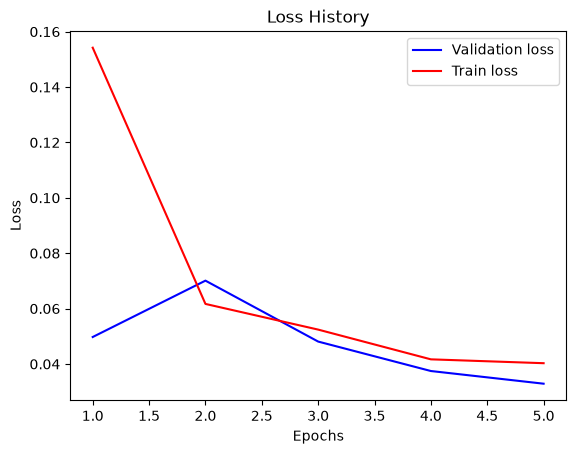

In [ ]:
# 학습 중 epoch에 따라 loss의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(history_dict["VLH"])+1), history_dict["VLH"], 'b', label="Validation loss")
plt.plot(range(1, len(history_dict["TLH"])+1), history_dict["TLH"], 'r', label="Train loss")
plt.title("Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

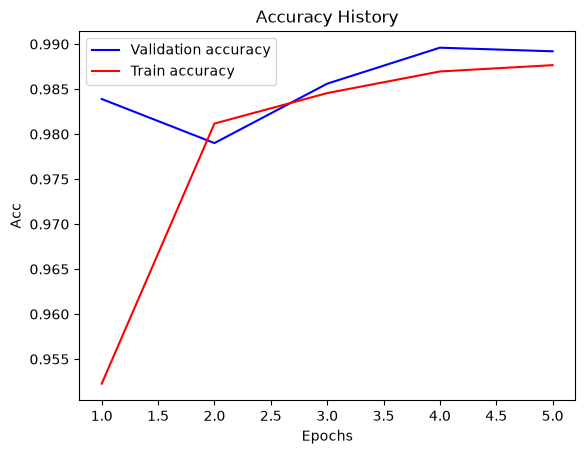

In [ ]:
# 학습 중 epoch에 따라 accuracy의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(history_dict["VAH"])+1), history_dict["VAH"], 'b', label="Validation accuracy")
plt.plot(range(1, len(history_dict["TAH"])+1), history_dict["TAH"], 'r', label="Train accuracy")
plt.title("Accuracy History")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.legend()
plt.show()

In [ ]:
report = classification_report(
    test_labels, test_preds,
    output_dict=True
)
print(classification_report(test_labels, test_preds))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       1.00      1.00      1.00      1032
           3       0.98      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       1.00      1.00      1.00       974
           9       1.00      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

